# Image processing notebook, Scinti2024_ZnO

## Settings

### Imports

First, we import all the necessary modules and support functions

In [14]:
import sys
sys.path.append(r'C:\Software\pyerre\framework')
sys.path.append(r'C:\Software\pyerre\proc_functions')
sys.path.append(r'C:\Software\pyninoise')

from magic_selectors import select_basedir, select_directory, \
    select_filesave_fits, select_fileopen_fits, select_roi, \
    select_multiple_rois

from mergers import simple_merge, mrg_medproj, mrg_avgproj_nan, multi_merge

from processors import test_proc, batch_proc, single_proc
from parameters import set_general_scope, set_group_scope, \
    set_params, param

from img_utils import get_img, write_img, crop_img

import numpy as np
import os

%gui qt

### Experiment parameters

Here, we define the experimental parameters

In [15]:
exp_params = {
    'name': 'ZnO',
    'beamline': 'ICON',
    'scintillator': 'LiF-ZnO, unknown thickness, (S/N ?)',
    'pix_size': 10.8, # pixel size in um
    'camera': 'Ikon-L DW936N-BV, S/N unknwon serial number',
    'camera_qe': 0.95, # quantum efficiency of the camera
    'lens': 'Nikkor? 50mm, f/1.4, S/N unknown number',
    'lens_diameter': 35, # lens diameter in mm
    'lens_dist': 350, # distance between lens and scintillator
    'neutron_flux_per_ma': 7.1e6, # flux in n/cm^2/s/mA
    'exposure_time': 1, # exposure time in seconds
    'target_exp': 1240 # target exposure in uAs
}

The following parameters can be computed from the others:

In [16]:
exp_params['p_capt_eff'] = exp_params['lens_diameter']**2/exp_params['lens_dist']**2/16
exp_params['lens_solid_angle'] = exp_params['p_capt_eff']*4*np.pi
exp_params['neutron_flux'] = exp_params['neutron_flux_per_ma']*exp_params['target_exp']/1000
exp_params['n_count'] = exp_params['neutron_flux']*exp_params['exposure_time']*(exp_params['pix_size']*1e-4)**2

### Base Directory

Then, we define the _**base directory**_ for the measurement campaign. All further directories and files will be defined relatively to this base diretory, so that the notebook can be used even if the data is moved somewhere else.

In [17]:
set_params(base_dir = r"M:/90_projects/93_data/P20240653")
# %msel select_directory('base_dir', default=r"M:/90_projects/93_data/P20240653")

The following parameter can be changed to True to reexecute the notebook skipping the test phases

In [18]:
set_params(skip_testing=False)

### 100nmREF

In [8]:
set_params(resol_imgf = r"04_evaluation/041_images/03_ndptpx/06_averaged/02_plated1um/AVG_05_1umREF.fits")
# %msel select_fileopen_fits('resol_imgf', default=r"04_evaluation/041_images/03_ndptpx/06_averaged/02_plated1um/AVG_05_1umREF.fits")

In [9]:
set_params(resol_dir = r"04_evaluation/041_images/03_ndptpx/06_averaged/05_1umREF")
# %msel select_directory('resol_dir', default=r"04_evaluation/041_images/03_ndptpx/06_averaged/05_1umREF")

Selection of the ROIs for the resolution

In [11]:
set_params(resol_rois = [[1067, 877, 56, 61], [981, 978, 58, 58], [913, 1373, 59, 63]])
# %msel select_multiple_rois('resol_rois', param('resol_dir'), default=[[1067, 877, 56, 61], [981, 978, 58, 58], [913, 1373, 59, 63]])

In [12]:
from img_utils import get_img, show_img
resol_img = np.nan_to_num(get_img(param('resol_imgf'), param('base_dir')))

The *meas_resol()* function measures the resolution by first identifying the main edge in each ROI, extracting an edge spread function (ESF), and computing the line spread function (LSF) as its derivate. The LSF is fitted using a Voigt function (convolution of a Gaussian and a Lorentzian). The two corresponding parameters (sigma and gamma) for each ROI are returned.

C:\ProgramData\anaconda3\lib\site-packages\numpy\lib\function_base.py:518: RuntimeWarning: Mean of empty slice.
  avg = a.mean(axis, **keepdims_kw)
C:\ProgramData\anaconda3\lib\site-packages\numpy\core\_methods.py:190: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


ValueError: array must not contain infs or NaNs

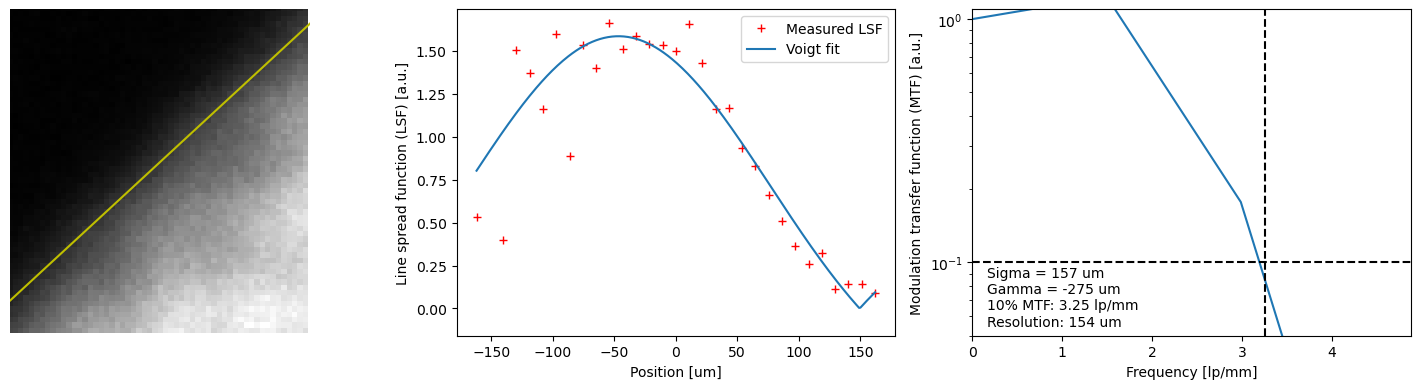

In [13]:
from resolution import meas_resol
sigma_vals, gamma_vals, mtf_vals = meas_resol(resol_img, param('resol_rois'), pix_size=exp_params['pix_size'])

We add the *sigma* and *gamma* average values to the list of experimental parameters

### 1umREF

In [27]:
set_params(resol_imgf = r"04_evaluation/041_images/03_ndptpx/04_reg/05_1umREF/Result of 05_1umREF0000.fits")
# %msel select_fileopen_fits('resol_imgf', default=r"04_evaluation/041_images/03_ndptpx/04_reg/05_1umREF/Result of 05_1umREF0000.fits")

In [13]:
set_params(resol_dir = r"04_evaluation/041_images/03_ndptpx/04_reg/05_1umREF")
# %msel select_directory('resol_dir', default=r"04_evaluation/041_images/03_ndptpx/04_reg/05_1umREF")

Selection of the ROIs for the resolution

In [14]:
set_params(resol_rois = [[929, 1097, 61, 68], [923, 1342, 41, 42], [1046, 912, 50, 54]])
# %msel select_multiple_rois('resol_rois', param('resol_dir'), default=[[929, 1097, 61, 68], [923, 1342, 41, 42], [1046, 912, 50, 54]])

In [15]:
from img_utils import get_img, show_img
resol_img = np.nan_to_num(get_img(param('resol_imgf'), param('base_dir')))

The *meas_resol()* function measures the resolution by first identifying the main edge in each ROI, extracting an edge spread function (ESF), and computing the line spread function (LSF) as its derivate. The LSF is fitted using a Voigt function (convolution of a Gaussian and a Lorentzian). The two corresponding parameters (sigma and gamma) for each ROI are returned.

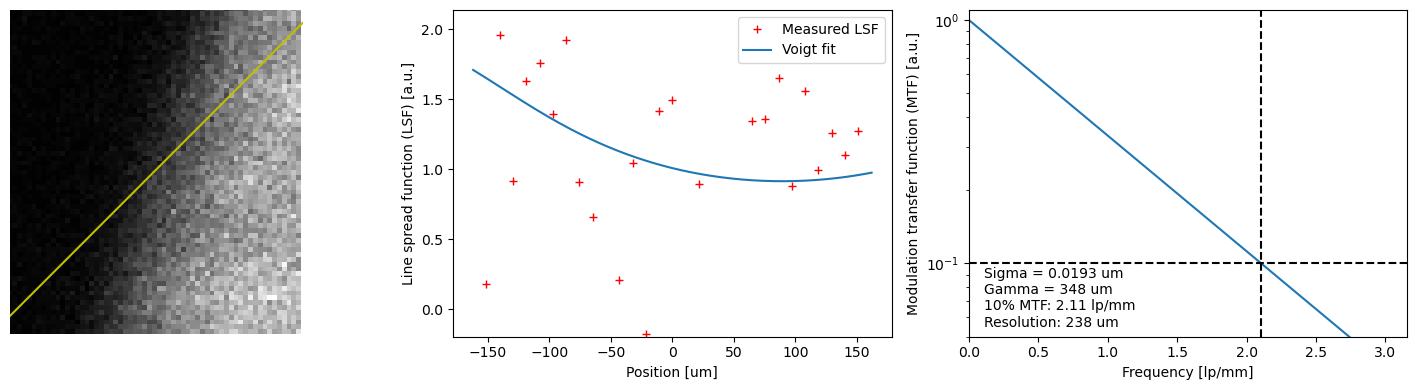

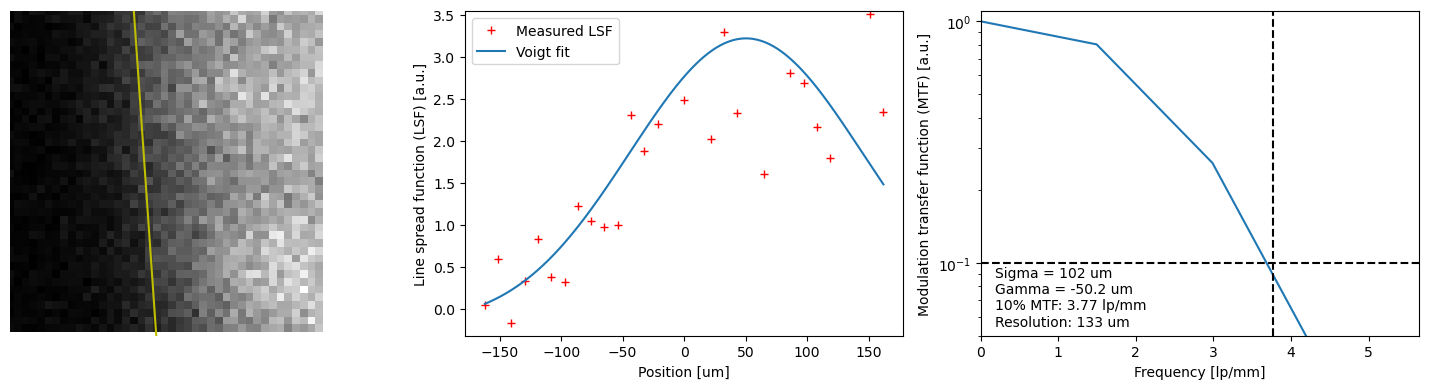

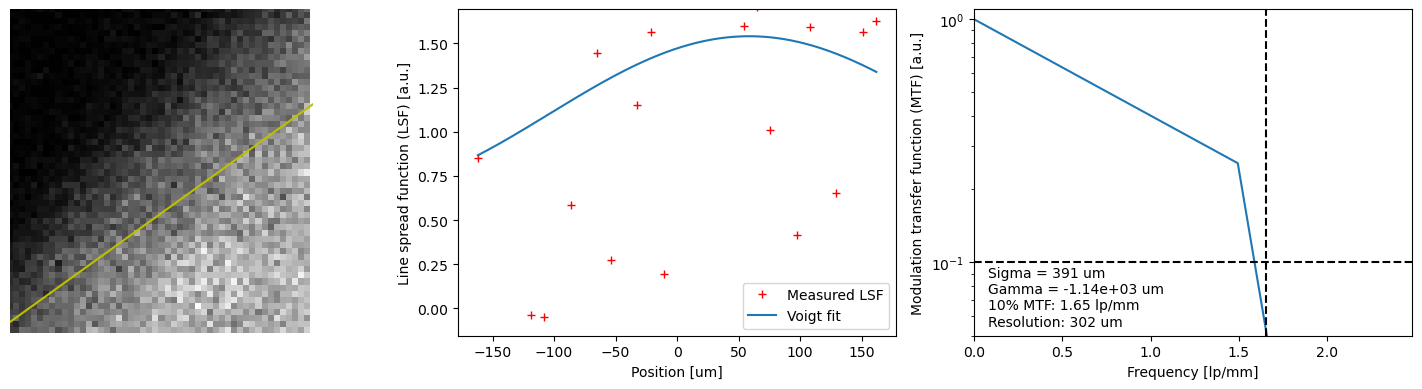

In [16]:
from resolution import meas_resol
sigma_vals, gamma_vals, mtf_vals = meas_resol(resol_img, param('resol_rois'), pix_size=exp_params['pix_size'])